<a href="https://colab.research.google.com/github/antoniosolis4536-collab/MIAAD/blob/main/Solis_Antonio_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Antonio Ismael Solis Martinez  

**Matrícula:** 276706

**Fecha:** Oct-08-2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [63]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico de la campaña del banco: una llamada a un cliente, con sus datos y el contexto económico del momento. |
| ¿Qué se predice? | Si el cliente contrata el depósito a plazo (`y` = si) o no (`y` = no). |
| ¿Qué tipo de problema es? | Clasificación binaria, con una clase minoritaria (los que contratan). |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Antes de llamar al cliente, para decidir a quién llamar. Ya se conoce el perfil del cliente (edad, ocupación, estado civil, escolaridad, `default`, `housing`, `loan`), su historial con campañas anteriores (`pdays`, `previous`, `poutcome`), el medio y la fecha planeada de contacto y los indicadores económicos del momento. |
| ¿Qué columnas no deberían usarse como características y por qué? | `duration`, porque la duración de la llamada solo se conoce cuando la llamada ya terminó, o sea después del evento que se quiere predecir. `y` es el objetivo. `campaign` también hay que vigilarla, porque cuenta los contactos incluyendo el último. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Creo que contrato entre 10% y 15% de los contactos, la mayoria de estas encuestas la mayoria dice que no.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas?  No creo que haya NaN, porque la pista dice que los faltantes vienen como unknown. Espero unknown sobre todo en default (muy poca gente declara si tiene crédito en incumplimiento) y en education, y menos en job, housing y loan. En default calculo algo así como 20% de las filas.

In [64]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
print("Dimensiones:", df.shape)

#  - el tipo de dato de cada columna,
print("Tipos de datos:")
print(df.dtypes)

#  - el número de valores únicos por columna, de menor a mayor.
print("Número de valores únicos por columna:")
print(df.nunique().sort_values())


Dimensiones: (41188, 21)
Tipos de datos:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object
Número de valores únicos por columna:
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26
cons.conf.idx   

In [65]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
print("Total de valores NaN: ", df.isnull().sum().sum())

#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
unknown = (df[categoricas]== "unknown").sum()
print("Filas con unknown:")
print(unknown[unknown > 0])

#  - ese conteo como porcentaje de las filas.
print("Porcentaje de filas con unknown:")
print(((unknown[unknown > 0] / df.shape[0])*100).round(2))

Total de valores NaN:  0
Filas con unknown:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64
Porcentaje de filas con unknown:
job           0.80
marital       0.19
education     4.20
default      20.87
housing       2.40
loan          2.40
dtype: float64


In [66]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("Filas duplicadas: ", df.duplicated().sum())

Filas duplicadas:  12


In [67]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
pdays_999 = (df["pdays"] == 999).sum()
print("Filas con pdays = 999: ", pdays_999)
print("Porcentaje de filas con pdays = 999: ",
 ((pdays_999 / df.shape[0])*100))

#  - una tabla de contingencia entre poutcome y (previous == 0),
print()
print(pd.crosstab(df["poutcome"], df["previous"] == 0))

#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.
print()
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays = 999:  39673
Porcentaje de filas con pdays = 999:  96.32174419733903

previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [68]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print("Edad mínima: ", df["age"].min())
print("Edad máxima: ", df["age"].max())

#  - cuántas llamadas tienen duration igual a 0,
print("Filas con duración = 0: ", (df["duration"] == 0).sum())

#  - el mínimo y el máximo de campaign,
print("Campaign mínimo: ", df["campaign"].min())
print("Campaign máximo: ", df["campaign"].max())

#  - cuántas filas tienen previous negativo.
print("Filas con previous negativo: ", (df["previous"] < 0).sum())

Edad mínima:  17
Edad máxima:  98
Filas con duración = 0:  4
Campaign mínimo:  1
Campaign máximo:  56
Filas con previous negativo:  0


**Tu observación.**

Nulos: no hay NaN (0 en todo el conjunto), pero hay faltantes escondidos como unknown: default 8,597 filas (20.87%), education 1,731 (4.20%), housing y loan 990 cada una (2.40%), job 330 (0.80%) y marital 80 (0.19%).


Duplicados: 12 filas idénticas (0.03%). Son pocas y no hay un ID para saber si son contactos distintos.
pdays = 999: es un código y no un número de días. Aparece en 39,673 filas (96.32%). Coincide con poutcome = nonexistent (35,563 filas, todas con previous = 0).


Inconsistencia entre columnas: de los 4,252 contactos con poutcome = failure (todos con previous > 0), 4,110 tienen pdays = 999. Es decir, sí hubo contacto previo pero pdays dice que no. Por eso pdays no es muy confiable y previous y poutcome sí cuadran entre sí.


Rangos: edad de 17 a 98 años (razonable), campaign de 1 a 56 (56 llamadas a una persona es raro pero posible), 0 valores negativos en previous, y 4 llamadas con duration = 0.


Dependen del significado de la variable: pdays = 999 (es un código), los unknown (es una categoría que quiere decir "no se sabe") y duration = 0 (una llamada que no se concretó).


Contra mi predicción: acerté en que no había NaN y en que default era la columna con más unknown (20.87%, justo lo que calculé). Lo que no esperaba fue el código 999 en pdays ni la inconsistencia con poutcome.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas?

Dejaría como una categoría más (unknown), sin imputar y sin eliminar filas. Son 8,597 filas (20.87%), eliminarlas me quita una quinta parte de los datos. Imputarla es adivinar el valor: entre los que sí declaran, casi todos son no (26,007 contra solo 3 yes en entrenamiento), así que imputar sería asumir que son no sin saberlo. Además, más adelante se ve que los unknown contratan 5.2% contra 12.9% de los no, o sea que el hecho de no saberlo ya trae información sobre el cliente.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Creo que van a ser casi iguales porque la division es estratifcada segun y, que justamente mantiene la proporcion de cada case en los 2 grupos.

In [69]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)
print("Tamaño de entrenamiento: ", entrenamiento.shape)
print("Tamaño de prueba: ", prueba.shape)

#  - el porcentaje de contratación (y igual a yes) en cada uno.
print(f"Contratación en entrenamiento: {(entrenamiento['y'] == 'yes').mean() * 100:.2f}%")
print(f"Contratación en prueba: {(prueba['y'] == 'yes').mean() * 100:.2f}%")


Tamaño de entrenamiento:  (32950, 21)
Tamaño de prueba:  (8238, 21)
Contratación en entrenamiento: 11.27%
Contratación en prueba: 11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [70]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Entrenamiento tiene 32,950 filas con 11.27% de contratación y prueba 8,238 filas con 11.26%. La diferencia es de una milésima de punto, así que mi predicción se cumplió. Con el 11.27% se puede saber que stratify hizo su trabajo y que la prueba representa lo mismo que el entrenamiento.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Seria alrededor de 88%, que es lo contrario de la tasa de contratatacion que obtuvimos en el ejercicio anterior (11-12%).

     Número  Porcentaje
y                      
no    29238       88.73
yes    3712       11.27

Razón entre clase mayoritaria y minoritaria: 7.88 a 1

Exactitud de responder siempre 'no': 11.27%


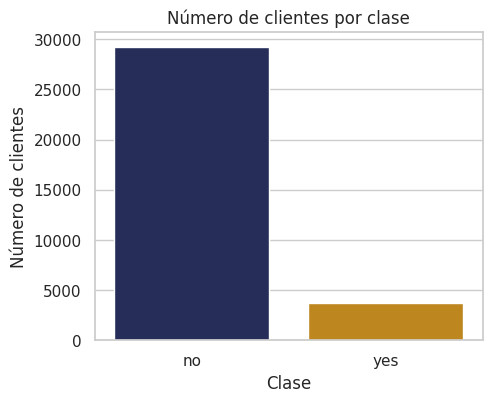

In [71]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
conteo = ent["y"].value_counts()
porcentaje = conteo / conteo.sum() * 100
print(pd.DataFrame({"Número": conteo, "Porcentaje": porcentaje.round(2)}))

#  - la razón entre la clase mayoritaria y la minoritaria,
print()
print(f"Razón entre clase mayoritaria y minoritaria: {conteo.max() / conteo.min():.2f} a 1")

#  - la exactitud de responder siempre "no",
print()
print(f"Exactitud de responder siempre 'no': {porcentaje.min():.2f}%")

#  - una gráfica de barras con el número de clientes por clase.
plt.figure(figsize=(5, 4))
sns.barplot(x=conteo.index, y=conteo.values, palette=COLORES_CLASE,
            hue=conteo.index, legend=False)
plt.title("Número de clientes por clase")
plt.xlabel("Clase")
plt.ylabel("Número de clientes")
plt.show()



**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. En entrenamiento hay 29,238 clientes con no (88.73%) y 3,712 yes (11.27%), una razon de 7.88 a 1. Responder siempre no da 88.73% de exactitud sin aprender nada.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Creo que duration va a ser la que mas diferencia (Llamadas largas son las de mas interes). Tambien indicadores economicos como euribor3m y nr.employed. La age y campaign no creo que separen mucho.

y                     no       yes
age               38.000    37.000
duration         164.000   448.000
campaign           2.000     2.000
pdays            999.000   999.000
previous           0.000     0.000
emp.var.rate       1.100    -1.800
cons.price.idx    93.918    93.200
cons.conf.idx    -41.800   -40.400
euribor3m          4.857     1.266
nr.employed     5195.800  5099.100



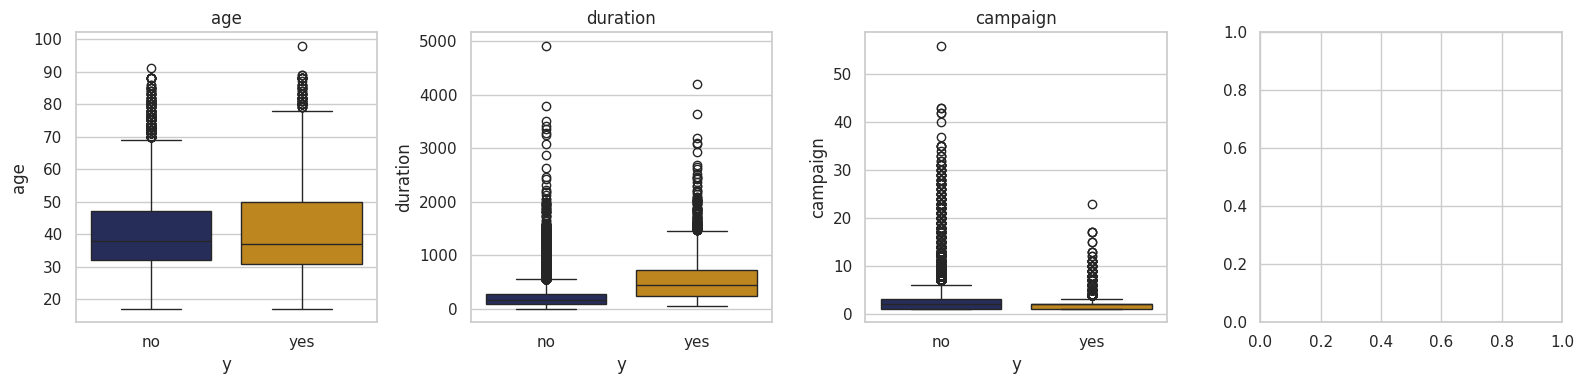

In [72]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
medianas = ent.groupby("y")[numericas].median().T
print(medianas)

#  - diagramas de caja por clase de al menos tres variables numéricas que elijas.
print()
variables_cajas = ["age", "duration", "campaign"]
fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for eje, variable in zip(ejes, variables_cajas):
    sns.boxplot(data=ent, x="y", y=variable, order=["no","yes"], hue="y",
                palette=COLORES_CLASE, legend=False, ax=eje)
    eje.set_title(variable)
    plt.tight_layout()
plt.show()


**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

- **Separan:** duration (mediana 448 s en yes contra 164 s en no) y euribor3m (1.27 contra 4.86). También se mueven emp.var.rate (−1.8 contra 1.1) y nr.employed (5099 contra 5196). Los que contratan fueron contactados cuando las tasas y el empleo estaban más bajos.
- **No separan o casi no:** age (37 contra 38), campaign (2 contra 2), previous (0 contra 0) y pdays (999 contra 999, porque casi todos son 999). cons.price.idx y cons.conf.idx se mueven muy poco (93.2 contra 93.9 y −40.4 contra −41.8).



Acerté en duration y euribor3m, y en que la edad y campaign no separan. Que previous y pdays no se vean con la mediana es porque más del 96% son sin contacto previo, ahí la mediana no dice nada y hay que ver tasas.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Creo que campaign, duration y previous, porque casi todos tiene 0.

In [73]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

fuera = []
for variable in numericas:
  fuera.append(((ent[variable] < limite_inf[variable]) | (ent[variable] > limite_sup[variable])).sum())

tabla_turkey = pd.DataFrame({
    "Limite_inferior": limite_inf,
    "Limite_superior": limite_sup,
    "Fuera": fuera
})
print(tabla_turkey)

                Limite_inferior  Limite_superior  Fuera
age                      9.5000          69.5000    368
duration              -221.0000         643.0000   2366
campaign                -2.0000           6.0000   1916
pdays                  999.0000         999.0000   1226
previous                 0.0000           0.0000   4534
emp.var.rate            -6.6000           6.2000      0
cons.price.idx          91.6965          95.3725      0
cons.conf.idx          -52.1500         -26.9500    359
euribor3m               -4.0815          10.3865      0
nr.employed           4905.6000        5421.6000      0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? previous (4,534) y pdays (1,226): la regla de Tukey no aplica porque más del 75% de los datos son iguales (previous = 0, pdays = 999) y el rango intercuartílico es 0. Los “atípicos” son los clientes con contacto previo, que son los más valiosos (con poutcome = success contrata el 64.9%). No se tocan.
campaign (1,916 fuera, límite 6): hasta 56 llamadas es raro pero posible, no es error de captura. Se podría limitar (tope de 6 o 10) o aplicar logaritmo, solo si el modelo es sensible a extremos.
duration (2,366 fuera): no vale la pena trabajarla, porque se va a excluir del modelo.
age (368, arriba de 69.5): edades de hasta 98 años son posibles (jubilados, que contratan más: 25.5%). No se eliminan.
cons.conf.idx (359): es un indicador mensual, el valor se repite para todas las llamadas de ese mes. No es un error.
Otros indicadores económicos (emp.var.rate, cons.price.idx, euribor3m, nr.employed): 0 valores fuera de límites.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Creo que logaritmo (np.log1p) redice mas la asimetria de campaign, porque la cola derecha es larga y el logaritmo comprime los valores grandes que la raiz cuadrada.

          Original  Raiz_cuadrada  Logaritmica
age           0.76           0.43         0.13
duration      3.33           1.20        -0.43
campaign      4.74           2.16         1.35


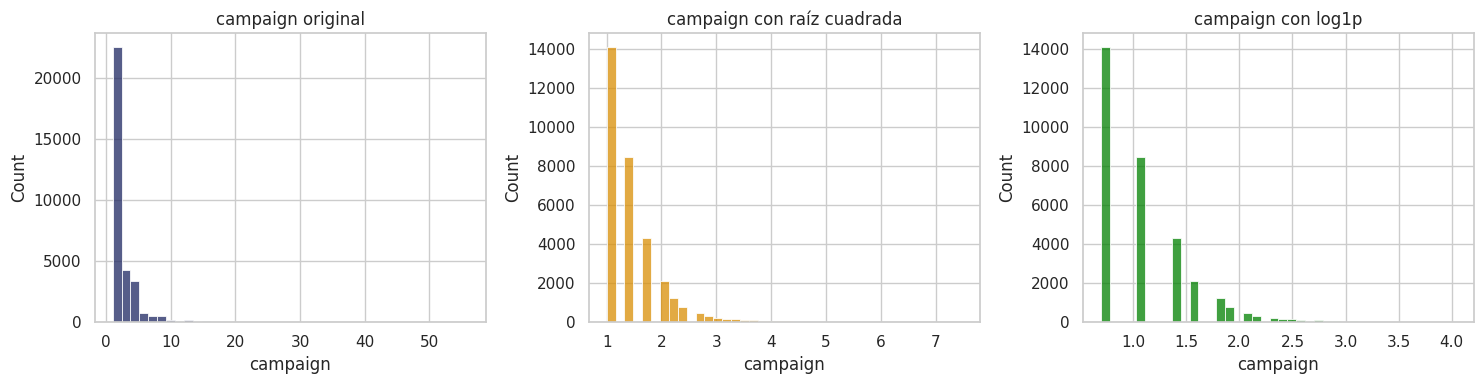

In [74]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
variables_asimetria = ["age", "duration", "campaign"]

tabla_asimetria = pd.DataFrame({
    "Original": ent[variables_asimetria].skew(),
    "Raiz_cuadrada": ent[variables_asimetria].apply(np.sqrt).skew(),
    "Logaritmica": ent[variables_asimetria].apply(np.log1p).skew()
}).round(2)
print(tabla_asimetria)

# Después grafica los histogramas de campaign: original y transformada.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(ent["campaign"], bins=40, color=AZUL, ax=ejes[0])
ejes[0].set_title("campaign original")

sns.histplot(np.sqrt(ent["campaign"]), bins=40, color=NARANJA, ax=ejes[1])
ejes[1].set_title("campaign con raíz cuadrada")

sns.histplot(np.log1p(ent["campaign"]), bins=40, color="green", ax=ejes[2])
ejes[2].set_title("campaign con log1p")

plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.

- **`campaign`:** es la más asimétrica. El logaritmo la baja de 4.74 a 1.35, mejor que la raíz (2.16). Aplicaría log1p solo si el modelo es sensible a la escala (regresión logística, SVM, redes). Aun así queda algo de asimetría.
- **`age`:** 0.76 es asimetría moderada, no la transformaría o lo haría solo si el modelo lo necesita.
- **`duration`:** el logaritmo la deja en −0.43 y la raíz en 1.20, pero como se va a excluir no tiene caso.
- En modelos de árboles no se transforma ninguna, porque no les afecta.


## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Creo que poutcome va a tener la categoria con mayor tasa ademas diria que tambien month y job.

In [75]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
print("Numero de categorias por variable:")
print((ent[categoricas].nunique()).sort_values())
#  - la tasa global de contratación en ent.
print()
tasa_global = ent["suscribe"].mean() * 100
print(f"Tasa global de contratación: {tasa_global:.2f}%")

Numero de categorias por variable:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa global de contratación: 11.27%


In [76]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
largo = ent.melt(id_vars="suscribe", value_vars = categoricas,
                 var_name="variable", value_name="categoria")

tasas = largo.groupby(["variable", "categoria"])["suscribe"].agg(clientes="count", tasa="mean").reset_index()
tasas["tasa"] = (tasas["tasa"] * 100).round(1)

#  - las 12 categorías con mayor tasa,
print("12 categorias con mayor tasa:")
print(tasas.sort_values("tasa", ascending=False).head(12))

#  - las 12 categorías con menor tasa,
print()
print("8 categorias con menor tasa:")
print(tasas.sort_values("tasa").head(8))

#  - las tablas de default, housing, loan y day_of_week.
for variable in ["default", "housing", "loan", "day_of_week"]:
  print()
  print(f"Tabla de {variable}:")
  print(tasas[tasas["variable"] == variable].drop(columns="variable").to_string(index=False))

# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

12 categorias con mayor tasa:
     variable   categoria  clientes  tasa
52   poutcome     success      1105  64.9
42      month         dec       143  50.3
45      month         mar       436  49.8
49      month         sep       464  44.6
48      month         oct       587  43.3
29        job     student       711  30.5
26        job     retired      1366  25.5
40      month         apr      2085  20.5
14  education  illiterate        16  18.8
39    marital     unknown        65  16.9
17  education     unknown      1397  14.8
0     contact    cellular     20908  14.7

8 categorias con menor tasa:
     variable    categoria  clientes  tasa
9     default          yes         3   0.0
8     default      unknown      6940   5.2
1     contact    telephone     12042   5.3
46      month          may     11011   6.3
22        job  blue-collar      7441   6.9
12  education     basic.9y      4826   7.6
28        job     services      3196   7.9
11  education     basic.6y      1865   8.4

Tabla 

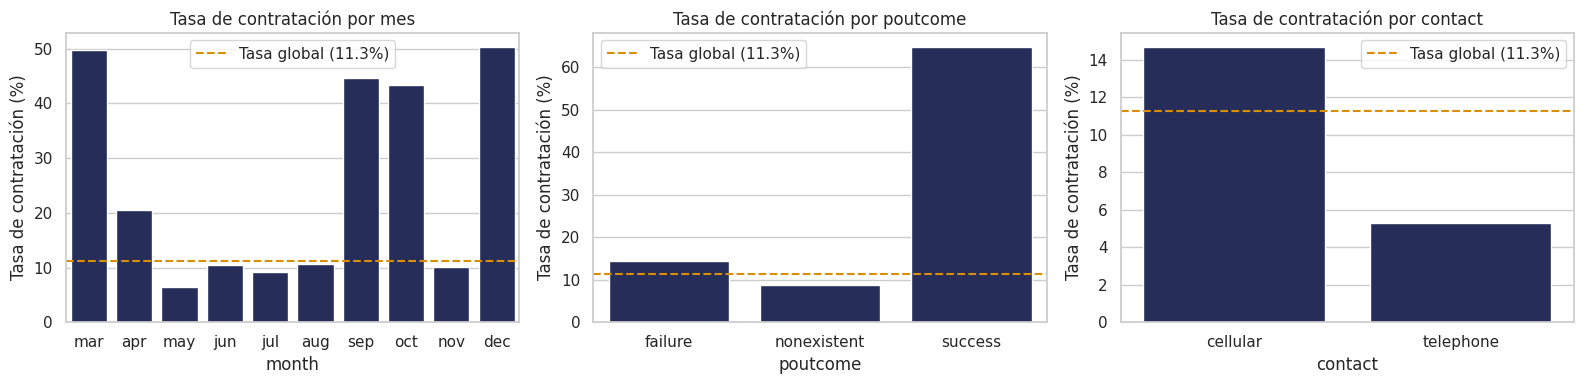

In [77]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
tasa_global = ent["suscribe"].mean() * 100

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

tasa_mes = ent.groupby("month")["suscribe"].mean().reindex(orden_meses) * 100
sns.barplot(x=tasa_mes.index, y=tasa_mes.values, color=AZUL, ax=ejes[0])
ejes[0].set_title("Tasa de contratación por mes")

tasa_poutcome = ent.groupby("poutcome")["suscribe"].mean() * 100
sns.barplot(x=tasa_poutcome.index, y=tasa_poutcome.values, color=AZUL, ax=ejes[1])
ejes[1].set_title("Tasa de contratación por poutcome")

tasa_contact = ent.groupby("contact")["suscribe"].mean() * 100
sns.barplot(x=tasa_contact.index, y=tasa_contact.values, color=AZUL, ax=ejes[2])
ejes[2].set_title("Tasa de contratación por contact")

for eje in ejes:
    eje.axhline(tasa_global, color=NARANJA, linestyle="--", label=f"Tasa global ({tasa_global:.1f}%)")
    eje.set_ylabel("Tasa de contratación (%)")
    eje.legend()
plt.tight_layout()
plt.show()


**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Mayor tasa: poutcome = success 64.9% (1,105 clientes), month diciembre 50.3% (143), marzo 49.8% (436), septiembre 44.6% (464) y octubre 43.3% (587), estudiantes 30.5% (711) y jubilados 25.5% (1,366). Los meses de mayor tasa son los de menos contactos.
Menor tasa: default = yes 0.0% (3 clientes), default = unknown 5.2% (6,940), contact = telephone 5.3% (12,042), month mayo 6.3% (11,011), blue-collar 6.9% (7,441). Mayo es el mes con más llamadas y de los que menos convierte.
Casi no separan: housing (10.9% a 11.6%), loan (11.2% a 11.3%) y day_of_week (10.2% a 12.0%), todas muy cerca de la tasa global.

Contra mi predicción: acerté con poutcome, month y job en las que más separan, y con housing, loan y day_of_week en las que casi no separan.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? unknown en default (5.2%) contra no (12.9%): que las tasas sean tan distintas dice que el unknown no es un faltante al azar, sino que agrupa a un tipo de cliente distinto (y tiene mucho peso, 6,940 clientes). Si lo imputara con no o lo eliminara perdería esa señal, por eso lo dejo como categoría propia.
default = yes (3 clientes) e illiterate (16 clientes, 18.8%): son categorías con muy pocos clientes, así que su tasa no es confiable (con 3 clientes, 0% no quiere decir nada, y con 16 un cliente más o menos mueve la tasa varios puntos). Hay que cuidarse de no sacar conclusiones ni dejar que el modelo se sobreajuste con eso. Las agruparía con otra categoría (por ejemplo, default en dos grupos: no y otro) o con unknown en el caso de education.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Creo que euribor3m con emp.var.rate y con nr.employed, porque los tres reflejan la situacion economica del mismo preriodo y se mueven juntos.

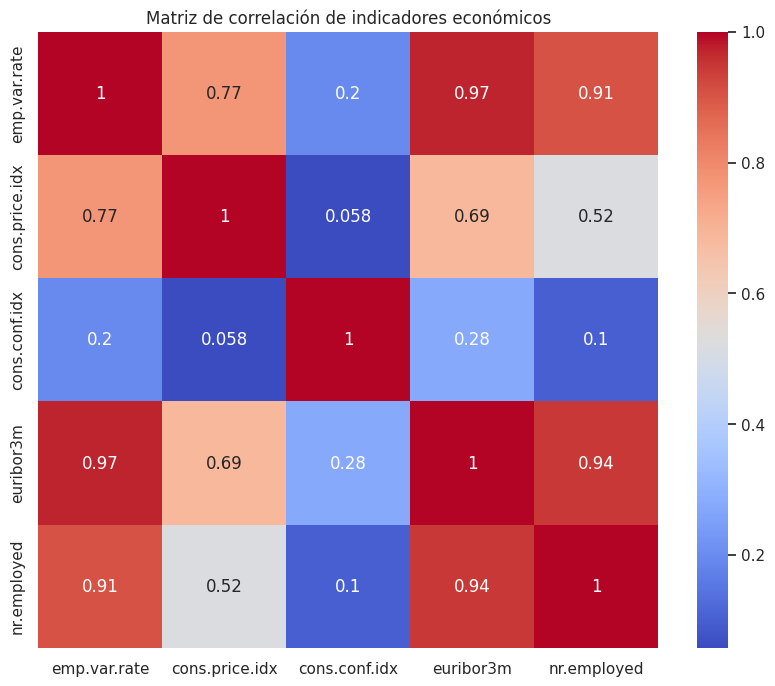

In [78]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
plt.figure(figsize=(10, 8))
sns.heatmap(ent[macro].corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación de indicadores económicos")
plt.show()


**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Los pares más correlacionados son euribor3m con emp.var.rate (0.97), euribor3m con nr.employed (0.94) y emp.var.rate con nr.employed (0.91). Después emp.var.rate con cons.price.idx (0.77). cons.conf.idx es la más independiente.

Decisión: los tres primeros son prácticamente la misma información, son redundantes. Para modelos lineales (colinealidad) dejaría solo uno (por ejemplo euribor3m) o usaría regularización. En árboles no hace daño pero tampoco aporta. Mi predicción fue correcta

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [79]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
ent.groupby("y")["duration"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.1,208.3,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.4,397.5,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. No la incluiría. duration es la duración de la última llamada, y se conoce hasta que la llamada termina, o sea cuando ya se sabe si el cliente contrató o no. Para decidir a quién llamar, ese valor todavía no existe. Se ve en los datos: la mediana es 448 s en yes contra 164 s en no, la media 549 contra 221 y el mínimo de los yes es 63 s (ningún cliente contrató con una llamada de menos de 63 s). Es una variable muy fuerte, pero es fuga de información: el modelo se vería muy bien en pruebas y no serviría en la práctica. Solo la usaría como referencia (benchmark) para ver qué tan bien se podría predecir con ella, nunca en el modelo final.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Dividir al azar mezcla contactos de todas las fechas, entonces el modelo entrena con llamadas de fechas posteriores a algunas de prueba. Es decir, se ve el "futuro". Además, los indicadores económicos casi identifican la fecha (euribor3m tiene solo 316 valores distintos en 41,188 filas), así que una llamada de prueba tiene vecinas del mismo día en entrenamiento y es más fácil acertarle. Todo esto hace que la evaluación salga mejor de lo que realmente sería con campañas futuras. Para un modelo que se usará hacia adelante conviene dividir por tiempo (entrenar con lo más antiguo y probar con lo más reciente) o validar con validación cruzada temporal.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| **Variable no utilizable.** `duration` solo se conoce al terminar la llamada: mediana 448 s en `yes` contra 164 s en `no`, y ningún `yes` con menos de 63 s. | Excluirla del modelo (fuga de información). Usarla solo como referencia. | Preprocesamiento (selección de variables) |
| **Códigos especiales.** `pdays = 999` en 39,673 filas (96.32%); además 4,110 de 4,252 contactos con `poutcome = failure` tienen 999 aunque `previous` > 0. | Crear un indicador `contactado_antes` (con `previous` y `poutcome`) y tratar 999 como "sin dato", no como 999 días. | Preprocesamiento |
| **Valores faltantes.** `unknown` en `default` (20.87% de las filas), `education` (4.20%), `housing` y `loan` (2.40%), `job` (0.80%). `default = unknown` contrata 5.2% contra 12.9% de `no`. | Dejar `unknown` como categoría propia y no imputar. | Preprocesamiento (codificación) |
| **Desbalance.** 11.27% de contratación (7.88 a 1). Responder siempre `no` da 88.73% de exactitud. | No usar la exactitud: evaluar con recall, precisión, F1 y AUC. Validación estratificada y probar `class_weight` o rebalanceo. | Evaluación y modelos |
| **Redundancia.** `euribor3m` con `emp.var.rate` 0.97, con `nr.employed` 0.94; `emp.var.rate` con `nr.employed` 0.91. | Quedarse con uno (por ejemplo `euribor3m`) o usar regularización en modelos lineales. | Preprocesamiento y modelos |
| **Asimetría.** `campaign` tiene 4.74; con `log1p` baja a 1.35 (con raíz, 2.16). | Aplicar `log1p` a `campaign` solo para modelos sensibles a la escala (lineales, SVM, redes). En árboles no. | Preprocesamiento |
| **Atípicos.** `campaign` tiene 1,916 registros fuera de Tukey (límite 6, máximo 56); en `previous` y `pdays` el rango intercuartílico es 0 y la regla no aplica. | No eliminar registros. Limitar `campaign` (tope) o usar log, y dejar `previous` como está. | Preprocesamiento |
| **Categorías con pocos clientes.** `default = yes` (3 clientes, 0.0%) e `illiterate` (16 clientes, 18.8%). | Agruparlas con otra categoría para no sobreajustar. | Preprocesamiento (codificación) |
| **Variables que casi no separan.** `housing` (10.9% a 11.6%), `loan` (11.2% a 11.3%) y `day_of_week` (10.2% a 12.0%) contra una tasa global de 11.27%. | Baja prioridad: candidatas a quitar si el modelo necesita simplificarse. | Modelos (selección de variables) |
| **Orden temporal.** Los datos están ordenados por fecha y la contratación cambia mucho por mes (diciembre 50.3%, mayo 6.3%). | Dividir por tiempo en vez de al azar, o validar con validación cruzada temporal. | Evaluación |
| **Duplicados.** 12 filas idénticas (0.03%). | Eliminarlas antes de dividir, para que una copia no caiga en entrenamiento y otra en prueba. | Preprocesamiento |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. - Con el conjunto total (parte B): descripción de la estructura, tipos, valores únicos, unknown, duplicados, consistencia entre columnas (pdays y poutcome) y rangos. Son verificaciones de estructura o del significado de las variables, no usan la variable objetivo ni calculan parámetros que luego se apliquen al modelo.
- Solo con entrenamiento (partes D, E y F): distribución del objetivo, medianas por clase, límites de Tukey, asimetría, tasas de contratación por categoría y correlaciones. Todo esto relaciona las variables con y o calcula valores (cuartiles, tasas) que fundamentan decisiones de modelado.

Criterio: lo que no depende del objetivo ni genera parámetros para el modelo se puede hacer con todo. Lo que sí, se hace solo con entrenamiento, para que la prueba quede intacta.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Se sesgarían las decisiones que salen de calcular algo con los datos: los límites de Tukey, la decisión de qué categorías agrupar por tener pocos clientes, qué variables se consideran fuertes o débiles (las tasas por categoría, como housing o day_of_week) y qué transformación aplicar. Todas se ajustarían también a los datos de prueba. En la evaluación final se vería como métricas más optimistas de lo real (recall, F1, AUC un poco inflados), y no se sabría cuánto del buen resultado es del modelo y cuánto es porque ya se había visto la prueba.